In [3]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 41.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [4]:
!pip install easyocr

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 17.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 972.1/972.1 kB 18.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [easyocr]


In [5]:
!unzip /content/Human_Fall.v1i.yolov11.zip

Streaming output truncated to the last 5000 lines.
  inflating: train/labels/people-4845-_jpg.rf.5a437b7d3bf3a2a56ae8c7ccc8655053.txt  
  inflating: train/labels/people-4927-_jpg.rf.9a853189cfb40157e0dab379831b4fce.txt  
  inflating: train/labels/people-6002-_jpg.rf.4ea51963c00667b5be08822d8ef27418.txt  
  inflating: train/labels/people-6000-_jpg.rf.437ca49486364f43dd26fb7f686e154a.txt  
  inflating: train/labels/people-5958-_jpg.rf.b5d388bea57d22444903698745b324a3.txt  
  inflating: train/labels/E-144-_png.rf.31c45067dc63011806f99d501a389d19.txt  
  inflating: train/labels/people-4918-_jpg.rf.c2594a545de9b5ae1dd0db55f94e49f3.txt  
  inflating: train/labels/people-4762-_jpg.rf.44cd98cdd5c6fac5bc308a8cd4271e0b.txt  
  inflating: train/labels/people-3415-_jpg.rf.d48ff96790fab0c888ee6fa7a18a85c7.txt  
  inflating: train/labels/people-5983-_jpg.rf.d6bab699420db69108f3b5eccd9d4488.txt  
  inflating: train/labels/D-31-_png.rf.c71a898855b0d6b72667acb01a3cdf23.txt  
  inflating: train/labels/p

In [6]:
# importing dependencies
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt
import easyocr

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [7]:
model=YOLO("yolo11n.pt")


In [8]:
results = model.train(
    data="/content/data.yaml",
    epochs=100,
    imgsz=640,
    save=True,
    save_period=5
)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, 

In [14]:
img=cv2.imread("/content/train/images/132_png.rf.bab54e0ca032f789d0657a0b83e5071b.jpg")

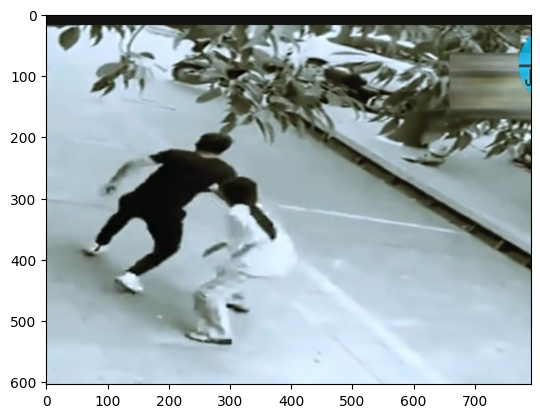

In [15]:
plt.imshow(img)

In [17]:
!find /content/runs -name "best.pt"

/content/runs/detect/train/weights/best.pt


In [18]:
from ultralytics import YOLO

fine_tuned_model = YOLO("/content/runs/detect/train/weights/best.pt")

In [19]:
result=fine_tuned_model(img,save=True,conf=0.6)


0: 512x640 1 Person, 17.4ms
Speed: 5.2ms preprocess, 17.4ms inference, 2.2ms postprocess per image at shape (1, 3, 512, 640)
Results saved to /content/runs/detect/predict


In [20]:
x1,y1,x2,y2=result[0].boxes.xyxy[0].cpu().numpy().astype("int")

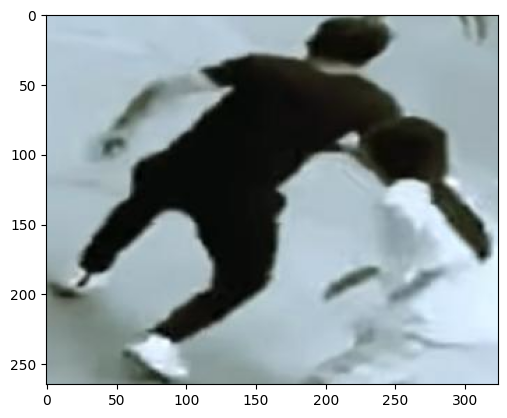

In [21]:
plt.imshow(img[y1:y2,x1:x2])

In [22]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [23]:
!find /content/runs -name "best.pt"

/content/runs/detect/train/weights/best.pt


In [24]:
import shutil
import os

source = "/content/runs/detect/train/weights/best.pt"

destination = "/content/drive/MyDrive/Human_Fall_best.pt"

shutil.copy2(source, destination)

print("Model saved successfully!")


Model saved successfully!


In [25]:
import os

print(os.path.exists("/content/drive/MyDrive/Human_Fall_best.pt"))

True


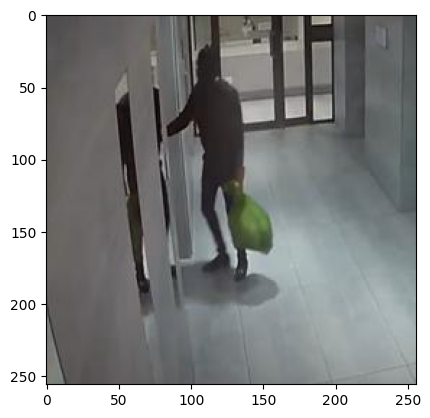

In [27]:
img=cv2.imread("/content/train/images/273_png.rf.568d440c64b7286bd88f20e668148739.jpg")
plt.imshow(img)


0: 640x640 1 Person, 20.2ms
Speed: 3.5ms preprocess, 20.2ms inference, 2.1ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict-2


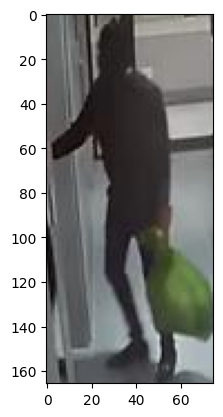

In [28]:
from ultralytics import YOLO

fine_tuned_model = YOLO("/content/runs/detect/train/weights/best.pt")
result=fine_tuned_model(img,save=True,conf=0.6)
x1,y1,x2,y2=result[0].boxes.xyxy[0].cpu().numpy().astype("int")
plt.imshow(img[y1:y2,x1:x2])

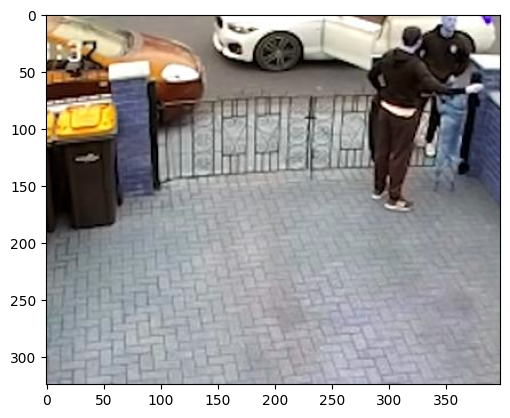

In [29]:
img=cv2.imread("/content/test/images/107_png.rf.b7f7c6988b371fbacc9632f701a75c43.jpg")
plt.imshow(img)


0: 544x640 (no detections), 7.9ms
Speed: 2.3ms preprocess, 7.9ms inference, 0.6ms postprocess per image at shape (1, 3, 544, 640)
Results saved to /content/runs/detect/predict-4
No objects detected with the current confidence threshold of 0.6.


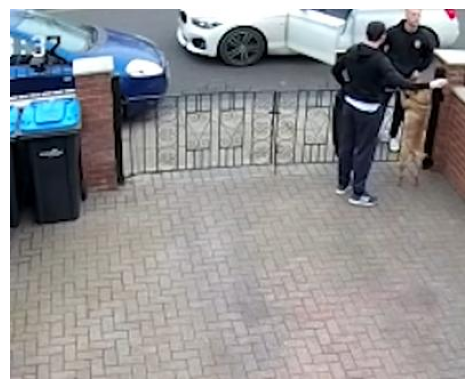

In [31]:
from ultralytics import YOLO
import matplotlib.pyplot as plt
import cv2

fine_tuned_model = YOLO("/content/runs/detect/train/weights/best.pt")
result = fine_tuned_model(img, save=True, conf=0.6)

# Safely check if any bounding boxes were detected
if len(result[0].boxes) > 0:
    x1, y1, x2, y2 = result[0].boxes.xyxy[0].cpu().numpy().astype("int")
    # Convert BGR to RGB for plotting with matplotlib
    cropped_img = cv2.cvtColor(img[y1:y2, x1:x2], cv2.COLOR_BGR2RGB)
    plt.imshow(cropped_img)
    plt.axis('off')
    plt.show()
else:
    print("No objects detected with the current confidence threshold of 0.6.")
    # Fallback to showing the whole image
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.axis('off')
    plt.show()

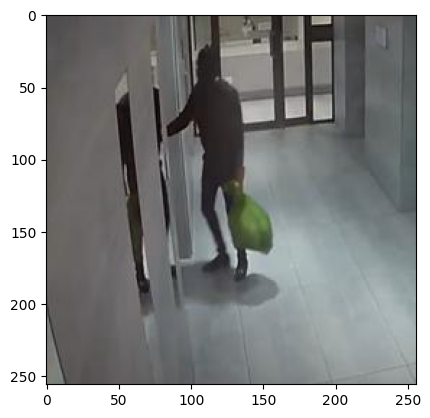

In [32]:
img=cv2.imread("/content/train/images/273_png.rf.568d440c64b7286bd88f20e668148739.jpg")
plt.imshow(img)


0: 640x640 1 Person, 28.6ms
Speed: 4.5ms preprocess, 28.6ms inference, 5.9ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict-5


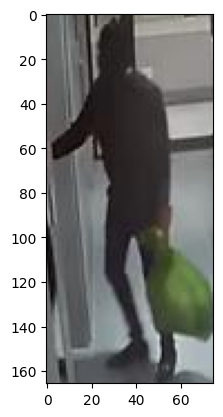

In [33]:
from ultralytics import YOLO

fine_tuned_model = YOLO("/content/runs/detect/train/weights/best.pt")
result=fine_tuned_model(img,save=True,conf=0.6)
x1,y1,x2,y2=result[0].boxes.xyxy[0].cpu().numpy().astype("int")
plt.imshow(img[y1:y2,x1:x2])


0: 640x640 1 Person, 19.5ms
Speed: 2.2ms preprocess, 19.5ms inference, 2.2ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict-6


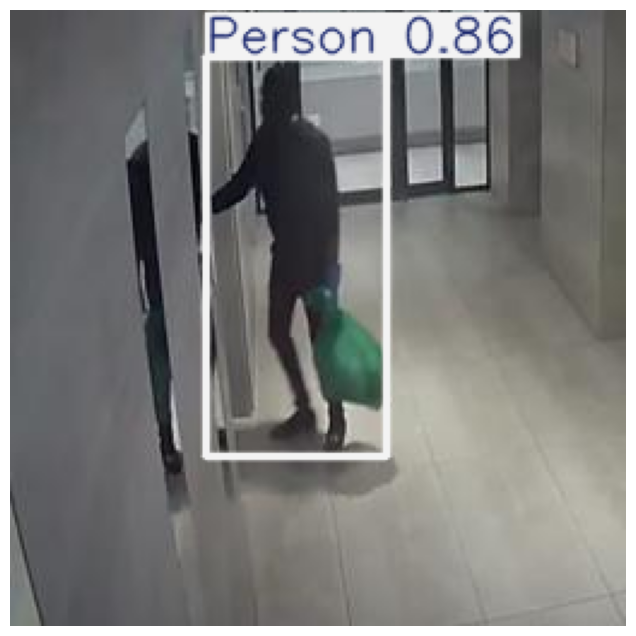

In [34]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

# Load your trained model
fine_tuned_model = YOLO("/content/runs/detect/train/weights/best.pt")

# Predict on the image
results = fine_tuned_model.predict(
    source=img,
    save=True,
    conf=0.6
)

# Draw bounding boxes on the complete image
boxed_img = results[0].plot()

# Display the image
plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(boxed_img, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

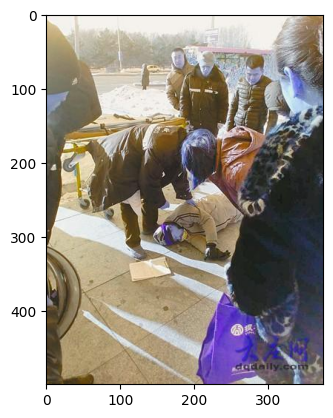

In [42]:
img=cv2.imread("/content/test/images/people-1021-_jpg.rf.9a47689beef0a4b694abf8c1b8023de4.jpg")
plt.imshow(img)


0: 640x480 1 Fall-Detected, 10.3ms
Speed: 3.2ms preprocess, 10.3ms inference, 1.7ms postprocess per image at shape (1, 3, 640, 480)
Results saved to /content/runs/detect/predict-11


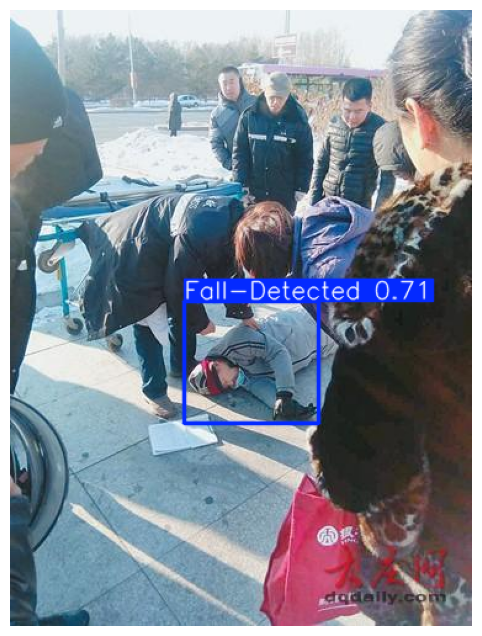

In [44]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

# Load your trained model
fine_tuned_model = YOLO("/content/runs/detect/train/weights/best.pt")

# Predict on the image
results = fine_tuned_model.predict(
    source=img,
    save=True,
    conf=0.6
)

# Draw bounding boxes on the complete image
boxed_img = results[0].plot()

# Display the image
plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(boxed_img, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

In [40]:
results = fine_tuned_model.predict(
    source=img,
    conf=0.01,
    iou=0.5,
    imgsz=640,
    save=True
)

print("Detections:", len(results[0].boxes))


0: 448x640 3 Fall-Detecteds, 13.5ms
Speed: 2.7ms preprocess, 13.5ms inference, 1.9ms postprocess per image at shape (1, 3, 448, 640)
Results saved to /content/runs/detect/predict-9
Detections: 3


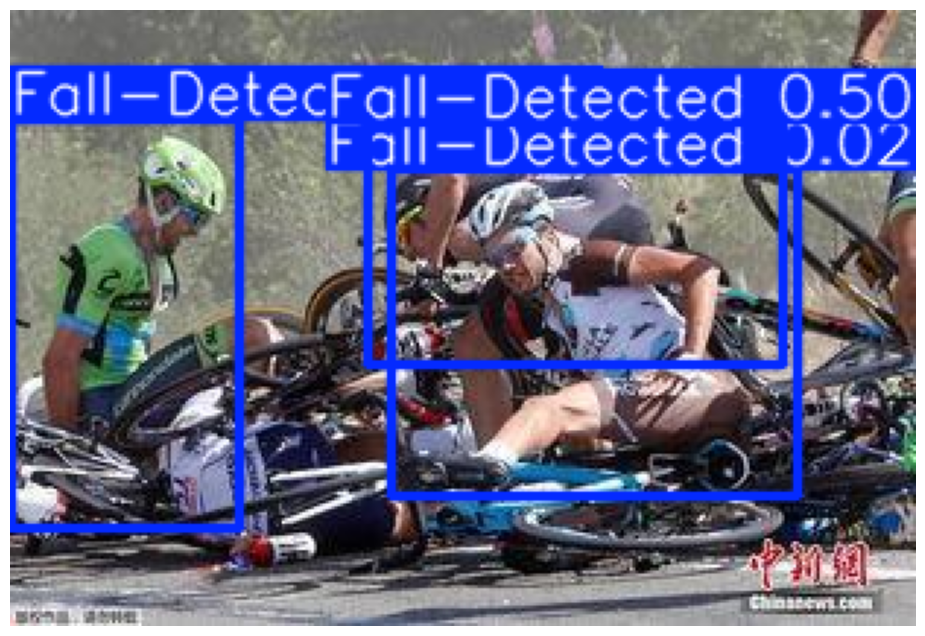

In [41]:
boxed_img = results[0].plot()

plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(boxed_img, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()